# Heart Disease Prediction System Assignment 
Submitted By: Rameen Muzammil Ejaz
Reg #: FA24-BSE-160
Section: A
Submitted To: Sir Rao Adeel

## Setup: Running This Notebook From Scratch

Run these commands in a terminal, inside this project's folder, before opening the notebook.

**1. Create and activate a virtual environment**

Windows: `python -m venv venv` then `venv\Scripts\activate`

macOS / Linux: `python3 -m venv venv` then `source venv/bin/activate`

**2. Install the required packages**
```
pip install -r requirements.txt
```

**3. Start Jupyter**
```
jupyter notebook
```

Keep `processed_cleveland.csv` in the same folder as this notebook. Every other CSV and the `.pkl` files are generated automatically when you run the notebook top to bottom.

## Introduction

##### **Definition**
A binary classification machine learning task that predicts whether a patient **has heart disease (Yes)** or **does not have heart disease (No)** using their clinical attributes.

##### **Application**
Used for learning data science, testing ML algorithms, and understanding which clinical findings are most strongly linked to heart disease. A model like this could support (not replace) a doctor's screening decision.

##### **Dataset**
UCI Heart Disease dataset, **Cleveland** subset (`processed.cleveland.data`, saved here as `processed_cleveland.csv`). It has 303 patients and 14 attributes (13 inputs + 1 output). Source: Detrano et al., Cleveland Clinic Foundation, via the UCI Machine Learning Repository.

##### **Feature Selection: Only the 4 Most Discriminating Attributes**
Out of the 13 input attributes, this notebook uses only the **4 attributes that best discriminate** between patients with and without heart disease. They are chosen in Step 5 using the Chi-Square test and Mutual Information.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Original Column** | **Possible Values** |
| --------------------------- | ------------------- | ------------------- |
| **ChestPain**      | cp    | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **MajorVessels**   | ca    | Zero, One, Two, Three |
| **ExerciseAngina** | exang | Yes, No |
| **Thal**           | thal  | Normal, Fixed Defect, Reversible Defect |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **HeartDisease**     | Yes, No |

### Examples (Heart Disease Dataset)

| ChestPain | MajorVessels | ExerciseAngina | Thal | HeartDisease |
| :-------- | :----------: | :------------: | :--- | :----------: |
| Typical Angina   | Zero  | No  | Fixed Defect      | No  |
| Asymptomatic     | Three | Yes | Normal            | Yes |
| Asymptomatic     | Two   | Yes | Reversible Defect | Yes |
| Atypical Angina  | Zero  | No  | Normal            | No  |
| Non-Anginal Pain | Zero  | No  | Normal            | No  |

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data (Handle Missing Values, Binarize Output)
- Step 4: Exploratory Data Analysis (EDA)
- Step 5: Feature Selection (Select the 4 Most Discriminating Attributes)
  - Step 5.1: Rank Attributes by Discriminating Power
  - Step 5.2: Build the Final Sample Data with the 4 Selected Attributes
- Step 6: Label Encoding the Sample Data
  - Step 6.1: Train the Label Encoders
  - Step 6.2: Label Encode the Output
  - Step 6.3: Label Encode the Input
- Step 7: Execute the Training Phase
  - Step 7.1: Split Sample Data into Training Data and Testing Data
  - Step 7.2: Split Input Vectors and Outputs / Labels of Training Data
  - Step 7.3: Train the Support Vector Classifier
  - Step 7.4: Save the Trained Model
- Step 8: Execute the Testing Phase
  - Step 8.1: Split Input Vectors and Outputs / Labels of Testing Data
  - Step 8.2: Load the Saved Model
  - Step 8.3: Make Predictions on Testing Data
  - Step 8.4: Calculate the Accuracy Score
  - Step 8.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
  - Step 8.6: Cross-Validation (Robustness Check)
- Step 9: Execute the Application Phase
  - Step 9.1: Take Input from User
  - Step 9.2: Convert User Input into Feature Vector
  - Step 9.3: Label Encoding of Feature Vector
  - Step 9.4: Load the Saved Model
  - Step 9.5: Apply Model and Return Prediction to the User
- Step 10: Execute the Feedback Phase
  - Step 10.1: Collect Feedback
  - Step 10.2: Make a List of Potential Improvements
  - Step 10.3: Improve the Model Based on Feedback
- Conclusion

## Code – Heart Disease Prediction

### Step 1: Import Libraries

In [ ]:
"""
Purpose of this section:
-------------------------
Imports the libraries needed for data handling, exploratory data analysis,
feature selection, label encoding, training a Support Vector Machine model,
evaluating it, and displaying results.
"""

# Numerical computing (arrays, math operations)
import numpy as np

# Data manipulation (DataFrames, reading/writing CSV)
import pandas as pd

# Saving and loading Python objects (trained model, label encoders)
import pickle

# Splitting data into training and testing sets, and cross-validation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# Converting categorical values into numeric codes
from sklearn.preprocessing import LabelEncoder

# Support Vector Machine (SVM) classifier
from sklearn import svm

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Feature selection: Mutual Information score
from sklearn.feature_selection import mutual_info_classif

# Feature selection: Chi-Square test of independence
from scipy.stats import chi2_contingency

# Clean table output for the final prediction
from prettytable import PrettyTable

# Plotting libraries (EDA charts and confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully")

### Step 2: Load Sample Data

In [ ]:
"""
Purpose of this section:
-------------------------
Loads the raw Cleveland Heart Disease dataset from a CSV file into a pandas
DataFrame. Missing values in the original file are written as '?', so we
tell pandas to read '?' as NaN (missing).
"""

# Read the CSV file ('processed_cleveland.csv' must be in the working directory)
raw_data = pd.read_csv("processed_cleveland.csv", na_values="?")

# Show all columns so nothing is hidden with '...'
pd.set_option("display.max_columns", None)

print("\n\nRaw Sample Data (first 10 rows):")
print("================================\n")
print(raw_data.head(10))

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

**Attribute descriptions (from the UCI documentation):**

| Column | Meaning |
| ------ | ------- |
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type: 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| restecg | Resting ECG result: 0 = normal, 1 = ST-T wave abnormality, 2 = left ventricular hypertrophy |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes, 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of the peak exercise ST segment: 1 = upsloping, 2 = flat, 3 = downsloping |
| ca | Number of major vessels (0-3) colored by fluoroscopy |
| thal | Thallium stress test: 3 = normal, 6 = fixed defect, 7 = reversible defect |
| num | Diagnosis: 0 = no heart disease, 1-4 = heart disease (increasing severity) |

In [ ]:
"""
Purpose of this section:
-------------------------
Helps us understand the dataset by printing:
1. The attribute (column) names
2. The number of instances (rows) and attributes
3. The data type of each attribute
4. Summary statistics
5. The number of missing values per attribute
"""

print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(raw_data.columns))

print("\n\nNumber of Instances:", raw_data.shape[0])
print("Number of Attributes:", raw_data.shape[1])

print("\n\nData Types:")
print("===========\n")
print(raw_data.dtypes)

print("\n\nSummary Statistics:")
print("===================\n")
print(raw_data.describe().round(2))

print("\n\nMissing Values per Attribute:")
print("=============================\n")
print(raw_data.isnull().sum())

#### Step 3.2: Pre-process Sample Data
Two pre-processing steps are needed:
- **Handle missing values:** 6 rows have a missing value in `ca` or `thal`. Since this is only about 2% of the data, these rows are removed.
- **Binarize the output:** `num` ranges from 0 to 4. Following the standard practice for this dataset, 0 means **No** heart disease and 1-4 means **Yes** (heart disease present).

In [4]:
"""
Purpose of this section:
-------------------------
1. Removes the rows that contain missing values.
2. Converts the 0-4 diagnosis column 'num' into a binary target:
   0 -> No heart disease, 1/2/3/4 -> Heart disease present.
"""

print("Rows before removing missing values:", raw_data.shape[0])

# Drop rows that have any missing value
clean_data = raw_data.dropna().reset_index(drop=True)
print("Rows after removing missing values: ", clean_data.shape[0])

# Create the binary target column (1 = disease, 0 = no disease)
clean_data["target"] = (clean_data["num"] > 0).astype(int)

print("\n\nTarget Class Distribution (0 = No Disease, 1 = Disease):")
print("=======================================================\n")
print(clean_data["target"].value_counts().sort_index())

Rows before removing missing values: 303
Rows after removing missing values:  297


Target Class Distribution (0 = No Disease, 1 = Disease):

target
0    160
1    137
Name: count, dtype: int64


### Step 4: Exploratory Data Analysis (EDA)

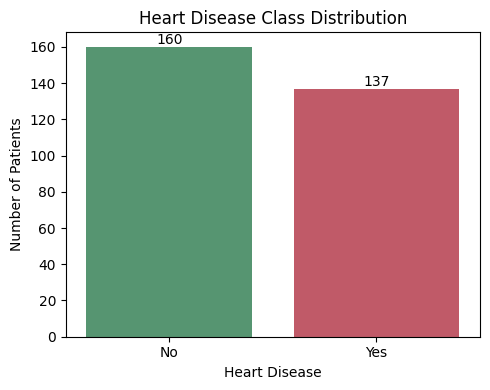

In [5]:
"""
Purpose of this section:
-------------------------
Visualizes the class balance of the output, so we know whether accuracy
alone is a fair metric (it is fair when classes are roughly balanced).
"""

plt.figure(figsize=(5, 4))
target_labels = clean_data["target"].map({0: "No", 1: "Yes"})
ax = sns.countplot(x=target_labels, hue=target_labels, order=["No", "Yes"],
                   palette={"No": "#4C9F70", "Yes": "#D1495B"}, legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

The two classes are roughly balanced (160 No vs. 137 Yes), so accuracy is a meaningful metric here, alongside precision and recall.

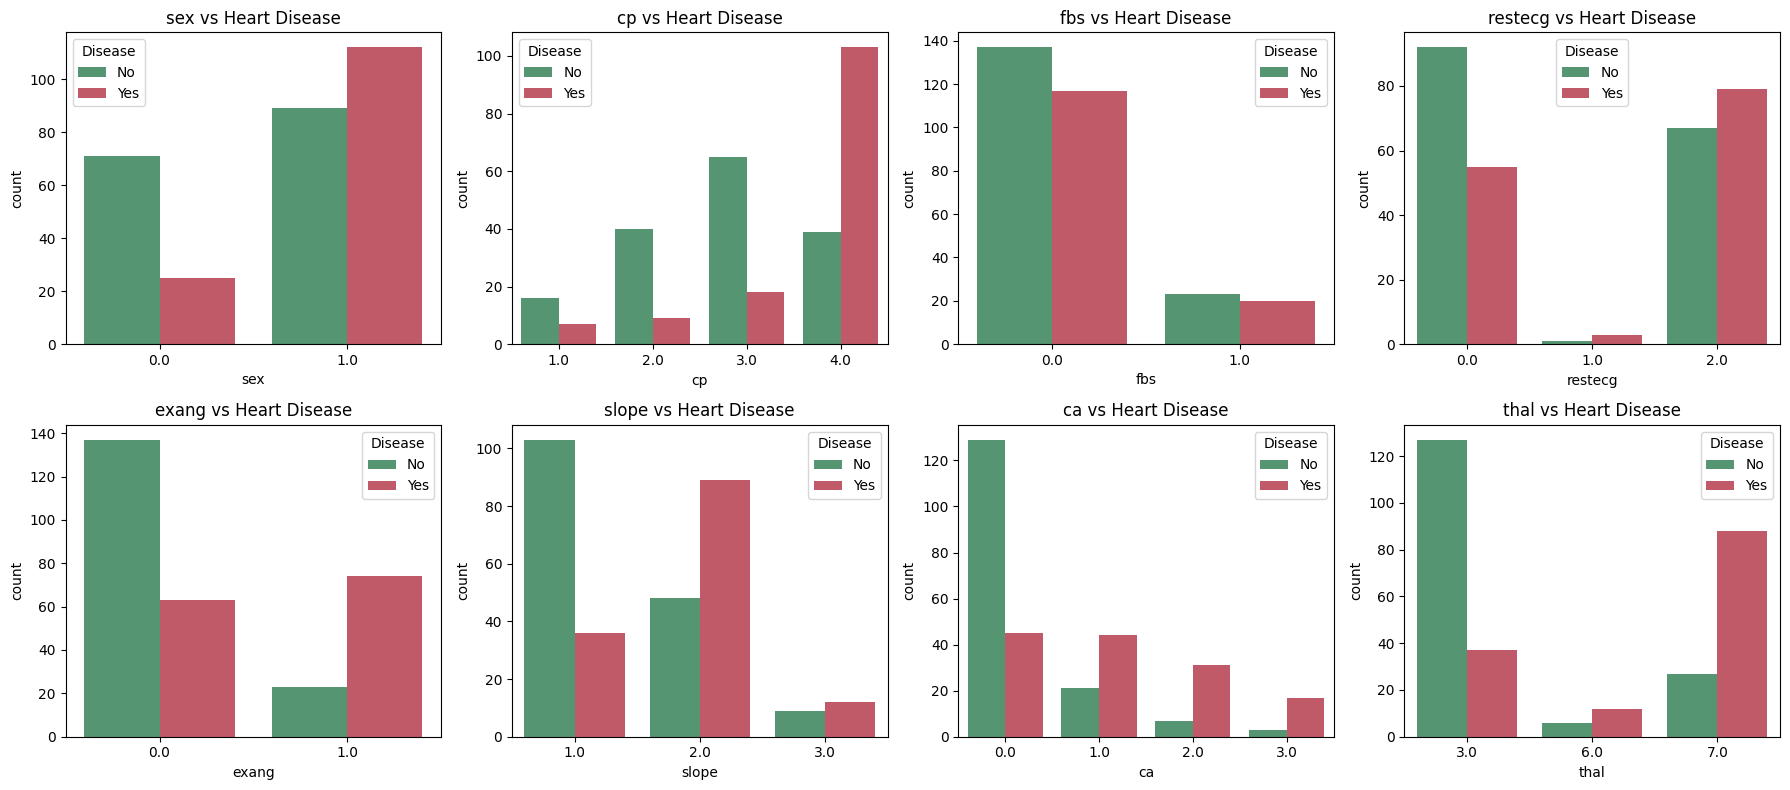

In [6]:
"""
Purpose of this section:
-------------------------
Compares each categorical attribute against the target. Attributes where the
bar heights differ a lot between 'No' and 'Yes' are good at discriminating
between the two classes.
"""

categorical_attributes = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), categorical_attributes):
    sns.countplot(data=clean_data, x=col, hue="target", palette=["#4C9F70", "#D1495B"], ax=ax)
    ax.set_title(f"{col} vs Heart Disease")
    ax.legend(title="Disease", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

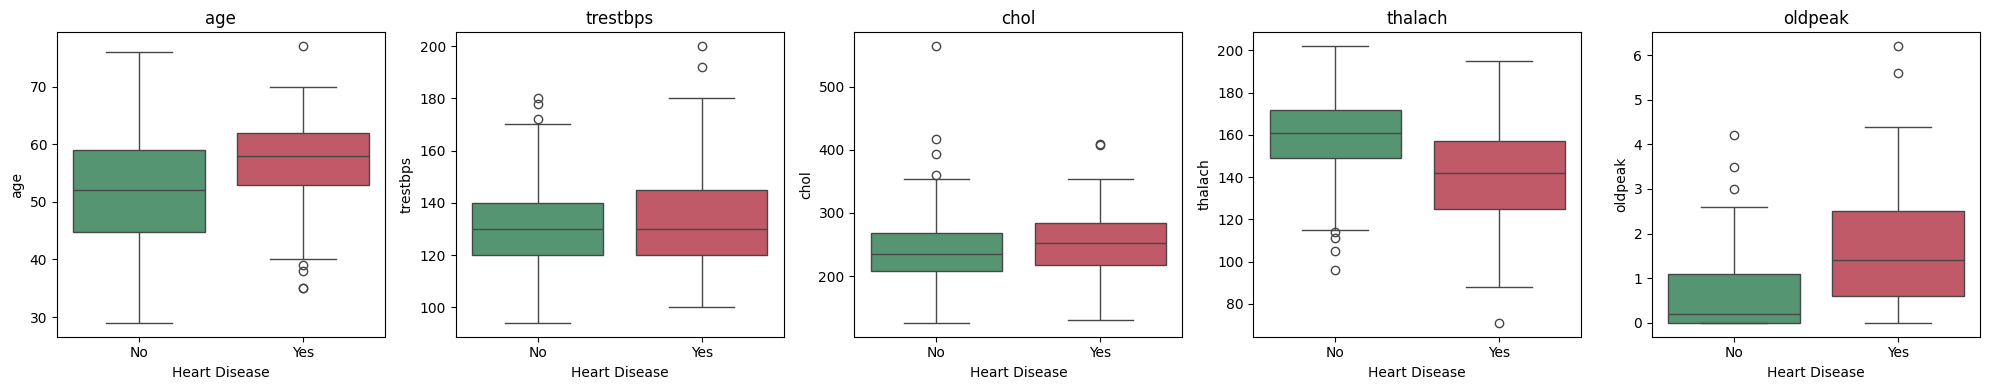

In [7]:
"""
Purpose of this section:
-------------------------
Compares the distribution of each numeric attribute between patients with
and without heart disease using box plots.
"""

numeric_attributes = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numeric_attributes):
    sns.boxplot(data=clean_data, x="target", y=col, hue="target",
                palette=["#4C9F70", "#D1495B"], legend=False, ax=ax)
    ax.set_xticks([0, 1], ["No", "Yes"])
    ax.set_xlabel("Heart Disease")
    ax.set_title(col)
plt.tight_layout()
plt.show()

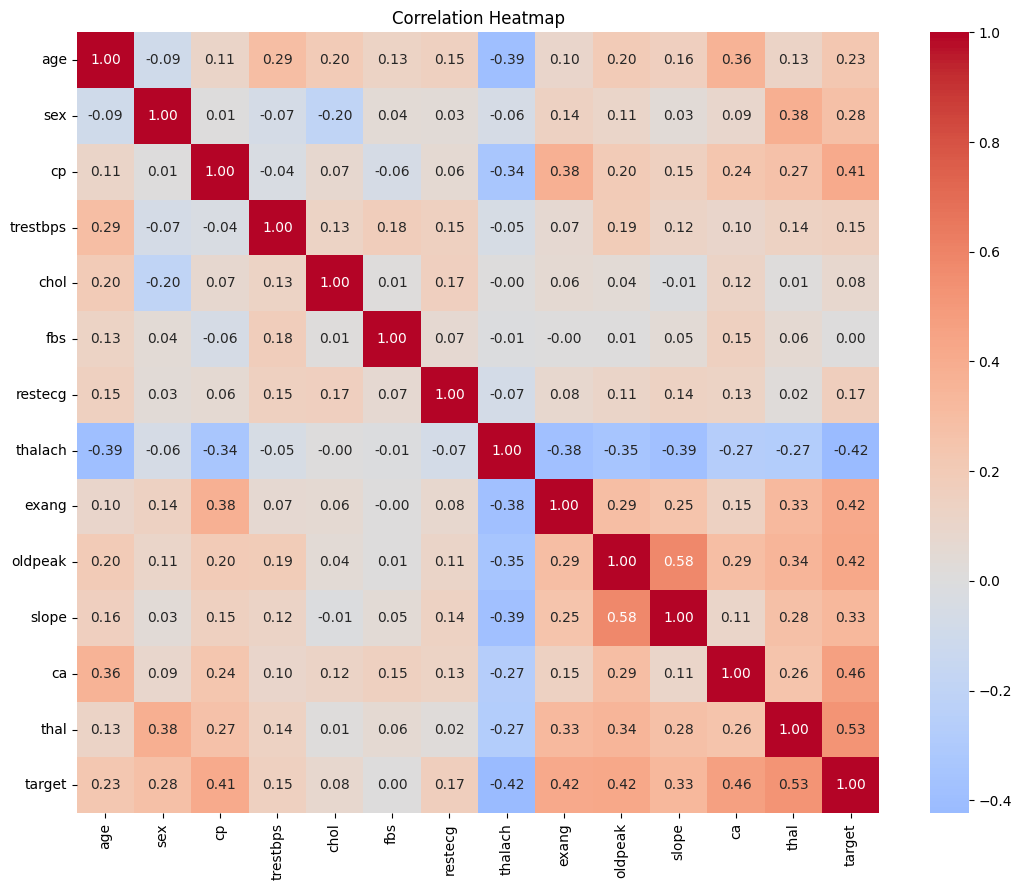

In [8]:
"""
Purpose of this section:
-------------------------
Shows the correlation between every attribute and the target in a heatmap.
"""

plt.figure(figsize=(11, 9))
sns.heatmap(clean_data.drop(columns=["num"]).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**EDA observations:**
- `cp` (chest pain): patients with **asymptomatic** chest pain (value 4) mostly have heart disease.
- `ca` (major vessels): the more vessels colored by fluoroscopy, the more likely heart disease is.
- `thal`: a **reversible defect** (value 7) is strongly linked to heart disease; **normal** (3) is mostly linked to no disease.
- `exang`: exercise-induced angina is much more common in patients with heart disease.
- `fbs` (fasting blood sugar) shows almost no difference between the two classes.

### Step 5: Feature Selection (Select the 4 Most Discriminating Attributes)

#### Step 5.1: Rank Attributes by Discriminating Power



Chi-Square Test Results (categorical attributes):

Attribute  Chi-Square  p-value  Cramer's V
     thal       82.46 1.24e-18       0.527
       cp       77.28 1.18e-16       0.510
       ca       72.30 1.37e-15       0.493
    exang       50.94 9.51e-13       0.414
    slope       43.47 3.63e-10       0.383
      sex       21.85 2.95e-06       0.271
  restecg        9.58 8.33e-03       0.180
      fbs        0.00 1.00e+00       0.000


Mutual Information Scores (all attributes):

Attribute  Mutual Information
     thal               0.146
       cp               0.137
       ca               0.128
  oldpeak               0.094
    exang               0.092
     chol               0.076
    slope               0.075
  thalach               0.065
      sex               0.040
  restecg               0.016
      age               0.000
 trestbps               0.000
      fbs               0.000


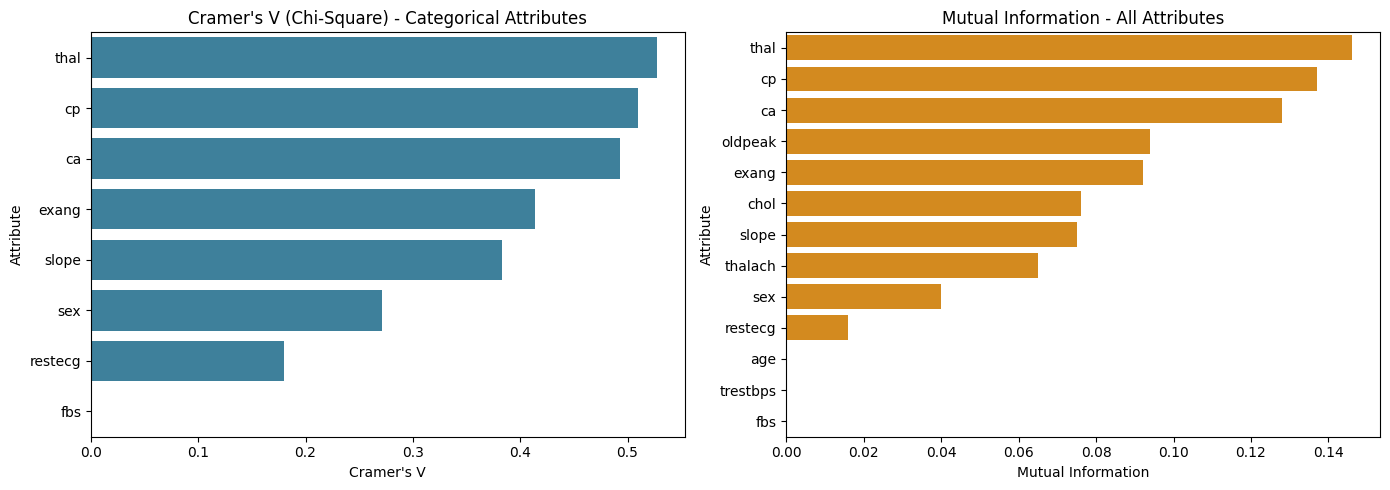

In [9]:
"""
Purpose of this section:
-------------------------
Measures how strongly each attribute discriminates between patients with and
without heart disease, using two methods:

1. Chi-Square test + Cramer's V (for categorical attributes):
   Tests whether the attribute and the target are independent. A higher
   Cramer's V (0 to 1) means a stronger association with the target.

2. Mutual Information (for all 13 attributes):
   Measures how much knowing the attribute reduces uncertainty about the
   target. Higher means more informative.
"""

# --- Method 1: Chi-Square + Cramer's V for categorical attributes
chi_square_results = []
for col in categorical_attributes:
    contingency_table = pd.crosstab(clean_data[col], clean_data["target"])
    chi2_value, p_value, _, _ = chi2_contingency(contingency_table)
    n = contingency_table.values.sum()
    k = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2_value / (n * k))
    chi_square_results.append([col, round(chi2_value, 2), p_value, round(cramers_v, 3)])

chi_square_df = pd.DataFrame(chi_square_results, columns=["Attribute", "Chi-Square", "p-value", "Cramer's V"])
chi_square_df = chi_square_df.sort_values("Cramer's V", ascending=False).reset_index(drop=True)
chi_square_df["p-value"] = chi_square_df["p-value"].map(lambda p: f"{p:.2e}")

print("\n\nChi-Square Test Results (categorical attributes):")
print("==================================================\n")
print(chi_square_df.to_string(index=False))

# --- Method 2: Mutual Information for all 13 input attributes
input_attributes = [c for c in clean_data.columns if c not in ("num", "target")]
is_discrete = [c in categorical_attributes for c in input_attributes]
mi_scores = mutual_info_classif(clean_data[input_attributes], clean_data["target"],
                                discrete_features=is_discrete, random_state=0)
mi_df = pd.DataFrame({"Attribute": input_attributes, "Mutual Information": mi_scores.round(3)})
mi_df = mi_df.sort_values("Mutual Information", ascending=False).reset_index(drop=True)

print("\n\nMutual Information Scores (all attributes):")
print("============================================\n")
print(mi_df.to_string(index=False))

# --- Plot both rankings side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=chi_square_df, x="Cramer's V", y="Attribute", color="#2E86AB", ax=axes[0])
axes[0].set_title("Cramer's V (Chi-Square) - Categorical Attributes")
sns.barplot(data=mi_df, x="Mutual Information", y="Attribute", color="#F18F01", ax=axes[1])
axes[1].set_title("Mutual Information - All Attributes")
plt.tight_layout()
plt.show()

**Result:** Both methods agree on the same top 4 attributes:

| Rank | Attribute | Meaning |
| :--: | :-------- | :------ |
| 1 | **thal** | Thallium stress test result |
| 2 | **cp** | Chest pain type |
| 3 | **ca** | Number of major vessels colored by fluoroscopy |
| 4 | **exang** | Exercise-induced angina |

These are all categorical, have p-values far below 0.05, and are clinically meaningful markers of heart disease. Only these 4 attributes are used from here on.

#### Step 5.2: Build the Final Sample Data with the 4 Selected Attributes

In [10]:
"""
Purpose of this section:
-------------------------
Keeps only the 4 selected attributes plus the target, and converts their
numeric codes into readable category names (just like the Titanic dataset uses
'Male'/'Female', 'First'/'Second'/'Third'). The result is saved as
'heart-sample-data.csv'.
"""

chest_pain_names = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-Anginal Pain", 4: "Asymptomatic"}
major_vessels_names = {0: "Zero", 1: "One", 2: "Two", 3: "Three"}
exercise_angina_names = {0: "No", 1: "Yes"}
thal_names = {3: "Normal", 6: "Fixed Defect", 7: "Reversible Defect"}
heart_disease_names = {0: "No", 1: "Yes"}

sample_data = pd.DataFrame({
    "ChestPain": clean_data["cp"].astype(int).map(chest_pain_names),
    "MajorVessels": clean_data["ca"].astype(int).map(major_vessels_names),
    "ExerciseAngina": clean_data["exang"].astype(int).map(exercise_angina_names),
    "Thal": clean_data["thal"].astype(int).map(thal_names),
    "HeartDisease": clean_data["target"].map(heart_disease_names),
})

sample_data.to_csv("heart-sample-data.csv", index=False, header=True)

print("\n\nSample Data with the 4 Selected Attributes (first 15 rows):")
print("============================================================\n")
print(sample_data.head(15))
print("\nShape:", sample_data.shape)
print("Missing values after mapping:", sample_data.isnull().sum().sum())
print("\nSaved: heart-sample-data.csv")



Sample Data with the 4 Selected Attributes (first 15 rows):

           ChestPain MajorVessels ExerciseAngina               Thal  \
0     Typical Angina         Zero             No       Fixed Defect   
1       Asymptomatic        Three            Yes             Normal   
2       Asymptomatic          Two            Yes  Reversible Defect   
3   Non-Anginal Pain         Zero             No             Normal   
4    Atypical Angina         Zero             No             Normal   
5    Atypical Angina         Zero             No             Normal   
6       Asymptomatic          Two             No             Normal   
7       Asymptomatic         Zero            Yes             Normal   
8       Asymptomatic          One             No  Reversible Defect   
9       Asymptomatic         Zero            Yes  Reversible Defect   
10      Asymptomatic         Zero             No       Fixed Defect   
11   Atypical Angina         Zero             No             Normal   
12  Non-Angina

### Step 6: Label Encoding the Sample Data (Input and Output Converted to Numeric Representation)

#### Step 6.1: Train the Label Encoders

In [11]:
"""
Purpose of this section:
-------------------------
Sets up and trains one LabelEncoder per attribute. Label Encoding converts
categorical values (e.g. 'Asymptomatic', 'Normal') into numeric codes that
the machine learning algorithm can work with.

Steps:
1. Define all possible categories for each attribute.
2. Create a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder on its categories.
"""

chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
major_vessels = pd.DataFrame({"MajorVessels": ["Zero", "One", "Two", "Three"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
thal = pd.DataFrame({"Thal": ["Normal", "Fixed Defect", "Reversible Defect"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

chest_pain_label_encoder = LabelEncoder()
major_vessels_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
thal_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

chest_pain_label_encoder.fit(np.ravel(chest_pain))
major_vessels_label_encoder.fit(np.ravel(major_vessels))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
thal_label_encoder.fit(np.ravel(thal))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show the mapping each encoder learned
encoders = {
    "ChestPain": chest_pain_label_encoder,
    "MajorVessels": major_vessels_label_encoder,
    "ExerciseAngina": exercise_angina_label_encoder,
    "Thal": thal_label_encoder,
    "HeartDisease": heart_disease_label_encoder,
}
print("\n\nLabel Encoder Mappings:")
print("=======================\n")
for name, encoder in encoders.items():
    mapping = {category: int(code) for category, code in zip(encoder.classes_, encoder.transform(encoder.classes_))}
    print(f"{name:15s}: {mapping}")



Label Encoder Mappings:

ChestPain      : {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-Anginal Pain': 2, 'Typical Angina': 3}
MajorVessels   : {'One': 0, 'Three': 1, 'Two': 2, 'Zero': 3}
ExerciseAngina : {'No': 0, 'Yes': 1}
Thal           : {'Fixed Defect': 0, 'Normal': 1, 'Reversible Defect': 2}
HeartDisease   : {'No': 0, 'Yes': 1}


#### Step 6.2: Label Encode the Output

In [12]:
"""
Purpose of this section:
-------------------------
Applies Label Encoding to the output attribute 'HeartDisease'
('No' -> 0, 'Yes' -> 1).
"""

sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output["HeartDisease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

print("\n\nHeartDisease Attribute After Label Encoding (first 10 rows):")
print("============================================================\n")
print(pd.DataFrame({"HeartDisease": sample_data["HeartDisease"],
                    "encoded_HeartDisease": sample_data_encoded_output["HeartDisease"]}).head(10))

sample_data_encoded_output.to_csv("heart-sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: heart-sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding (first 10 rows):

  HeartDisease  encoded_HeartDisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: heart-sample-data-encoded-output.csv


#### Step 6.3: Label Encode the Input

In [13]:
"""
Purpose of this section:
-------------------------
Applies Label Encoding to the 4 input attributes so the whole dataset
becomes numeric.
"""

sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded["ChestPain"] = chest_pain_label_encoder.transform(sample_data["ChestPain"])
sample_data_encoded["MajorVessels"] = major_vessels_label_encoder.transform(sample_data["MajorVessels"])
sample_data_encoded["ExerciseAngina"] = exercise_angina_label_encoder.transform(sample_data["ExerciseAngina"])
sample_data_encoded["Thal"] = thal_label_encoder.transform(sample_data["Thal"])

print("\n\nSample Data after Label Encoding (first 15 rows):")
print("=================================================\n")
print(sample_data_encoded.head(15))

sample_data_encoded.to_csv("heart-sample-data-encoded.csv", index=False, header=True)
print("\nSaved: heart-sample-data-encoded.csv")



Sample Data after Label Encoding (first 15 rows):

    ChestPain  MajorVessels  ExerciseAngina  Thal  HeartDisease
0           3             3               0     0             0
1           0             1               1     1             1
2           0             2               1     2             1
3           2             3               0     1             0
4           1             3               0     1             0
5           1             3               0     1             0
6           0             2               0     1             1
7           0             3               1     1             0
8           0             0               0     2             1
9           0             3               1     2             1
10          0             3               0     0             0
11          1             3               0     1             0
12          2             0               1     0             1
13          1             3               0     2  

### Step 7: Execute the Training Phase

#### Step 7.1: Split Sample Data into Training Data and Testing Data

In [14]:
"""
Purpose of this section:
-------------------------
Splits the dataset into Training Data (80%) and Testing Data (20%).
- shuffle=True mixes the rows before splitting, so both sets are representative.
- stratify keeps the same Yes/No ratio in both sets.
- random_state=0 makes the split reproducible (same split every run).
"""

training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"]
)

training_data_encoded.to_csv("heart-training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("heart-testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape: ", testing_data_encoded.shape)
print("\nSaved: heart-training-data-encoded.csv, heart-testing-data-encoded.csv")

Training Data shape: (237, 5)
Testing Data shape:  (60, 5)

Saved: heart-training-data-encoded.csv, heart-testing-data-encoded.csv


#### Step 7.2: Split Input Vectors and Outputs / Labels of Training Data

In [15]:
"""
Purpose of this section:
-------------------------
Separates the input features (first 4 columns) from the output label
(last column) in the training data.
"""

input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


#### Step 7.3: Train the Support Vector Classifier

In [16]:
"""
Purpose of this section:
-------------------------
Trains a Support Vector Classifier (SVC) on the training data. The SVC finds
the best boundary separating patients with and without heart disease.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 7.4: Save the Trained Model

In [17]:
"""
Purpose of this section:
-------------------------
Saves the trained SVC model to disk so it can be reused later without
retraining. The label encoders are saved too, because new patient data must
be encoded exactly the same way before the model can make a prediction.
"""

with open("heart_disease_model.pkl", "wb") as f:
    pickle.dump(svc_model, f)
print("Saved: heart_disease_model.pkl")

with open("heart_disease_label_encoders.pkl", "wb") as f:
    pickle.dump(encoders, f)
print("Saved: heart_disease_label_encoders.pkl")

Saved: heart_disease_model.pkl
Saved: heart_disease_label_encoders.pkl


### Step 8: Execute the Testing Phase

#### Step 8.1: Split Input Vectors and Outputs / Labels of Testing Data

In [18]:
"""
Purpose of this section:
-------------------------
Separates the input features and output labels of the testing data.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


#### Step 8.2: Load the Saved Model

In [19]:
"""
Purpose of this section:
-------------------------
Loads the saved SVC model from disk, exactly as it would be loaded in a new
session, to show that the model works without retraining.
"""

with open("heart_disease_model.pkl", "rb") as f:
    model = pickle.load(f)
print("Model loaded from heart_disease_model.pkl")
print(model)

Model loaded from heart_disease_model.pkl
SVC(gamma='auto', random_state=0)


#### Step 8.3: Make Predictions with the Trained Model on Testing Data

In [20]:
"""
Purpose of this section:
-------------------------
Uses the loaded model to predict the testing data, and stores the predictions
next to the actual labels.
"""

model_predictions = testing_data_encoded.copy()
model_predictions["Predictions"] = model.predict(input_vector_test)
model_predictions.to_csv("heart-model-predictions.csv", index=False, header=True)

print("\n\nPredictions Returned by heart_disease_model (first 20 test rows):")
print("=================================================================\n")
print(model_predictions.head(20))
print("\nSaved: heart-model-predictions.csv")



Predictions Returned by heart_disease_model (first 20 test rows):

     ChestPain  MajorVessels  ExerciseAngina  Thal  HeartDisease  Predictions
69           2             3               0     1             1            0
2            0             2               1     2             1            1
94           0             0               1     2             1            1
119          0             2               1     2             1            1
266          0             0               1     2             1            1
264          0             3               0     2             1            1
281          0             1               0     0             1            1
36           0             3               1     2             1            1
282          0             2               1     0             1            1
192          0             2               1     1             1            1
271          3             3               0     2             0         

#### Step 8.4: Calculate the Accuracy Score

In [21]:
"""
Purpose of this section:
-------------------------
Calculates the percentage of testing instances the model predicted correctly.
"""

model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.85


#### Step 8.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                precision    recall  f1-score   support

No Disease (0)       0.85      0.88      0.86        32
   Disease (1)       0.85      0.82      0.84        28

      accuracy                           0.85        60
     macro avg       0.85      0.85      0.85        60
  weighted avg       0.85      0.85      0.85        60


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     28                   4
Actual: Disease                         5                  23


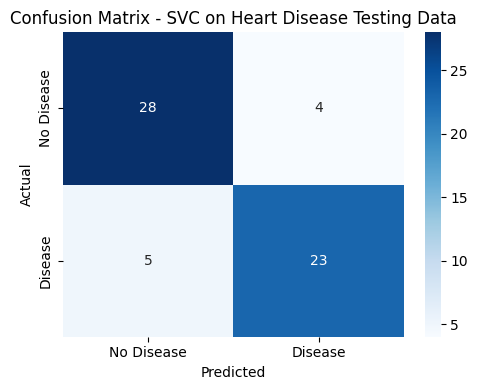

In [22]:
"""
Purpose of this section:
-------------------------
Accuracy alone can hide important errors. In medical screening, missing a
sick patient (a false negative) is especially costly, so we also report:
- Precision: of all patients predicted 'Disease', how many actually have it?
- Recall: of all patients who actually have disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: counts of correct and incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Disease (0)", "Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(conf_matrix,
                              index=["Actual: No Disease", "Actual: Disease"],
                              columns=["Predicted: No Disease", "Predicted: Disease"])
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

#### Step 8.6: Cross-Validation (Robustness Check)

In [23]:
"""
Purpose of this section:
-------------------------
A single 80/20 split depends on which patients happened to land in the test
set. 5-fold cross-validation trains and tests the model 5 times on different
splits and averages the results, giving a more reliable estimate.
"""

cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = cross_val_score(svm.SVC(gamma="auto", random_state=0),
                            sample_data_encoded.iloc[:, :-1],
                            sample_data_encoded.iloc[:, -1],
                            cv=cv_folds, scoring="accuracy")

print("\n\n5-Fold Cross-Validation Accuracy:")
print("=================================\n")
for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score:.2f}")
print(f"\nMean accuracy: {cv_scores.mean():.2f}  (+/- {cv_scores.std():.2f})")



5-Fold Cross-Validation Accuracy:

Fold 1: 0.85
Fold 2: 0.83
Fold 3: 0.73
Fold 4: 0.78
Fold 5: 0.76

Mean accuracy: 0.79  (+/- 0.04)


### Step 9: Execute the Application Phase

#### Step 9.1: Take Input from User

In [24]:
"""
Purpose of this section:
-------------------------
Takes a new patient's data. A demo patient is pre-filled so the notebook runs
top to bottom without typing. To enter your own values interactively, replace
the four lines below with:

    chest_pain_input = input("Chest Pain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
    major_vessels_input = input("Major Vessels (Zero, One, Two, Three): ").strip()
    exercise_angina_input = input("Exercise Angina (Yes, No): ").strip()
    thal_input = input("Thal (Normal, Fixed Defect, Reversible Defect): ").strip()
"""

chest_pain_input = "Asymptomatic"
major_vessels_input = "Two"
exercise_angina_input = "Yes"
thal_input = "Reversible Defect"

print(f"ChestPain: {chest_pain_input}, MajorVessels: {major_vessels_input}, "
      f"ExerciseAngina: {exercise_angina_input}, Thal: {thal_input}")

ChestPain: Asymptomatic, MajorVessels: Two, ExerciseAngina: Yes, Thal: Reversible Defect


#### Step 9.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [25]:
"""
Purpose of this section:
-------------------------
Converts the text input into a feature vector (a one-row DataFrame) with the
same columns, in the same order, as the training data.
"""

user_input = pd.DataFrame({
    "ChestPain": [chest_pain_input],
    "MajorVessels": [major_vessels_input],
    "ExerciseAngina": [exercise_angina_input],
    "Thal": [thal_input],
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

      ChestPain MajorVessels ExerciseAngina               Thal
0  Asymptomatic          Two            Yes  Reversible Defect


#### Step 9.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [26]:
"""
Purpose of this section:
-------------------------
Encodes the user's input with the saved label encoders, loaded from disk, so
the encoding is identical to the one used during training.
"""

with open("heart_disease_label_encoders.pkl", "rb") as f:
    loaded_encoders = pickle.load(f)

unseen_data_features = user_input.copy()
for column in ["ChestPain", "MajorVessels", "ExerciseAngina", "Thal"]:
    unseen_data_features[column] = loaded_encoders[column].transform(user_input[column])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   ChestPain  MajorVessels  ExerciseAngina  Thal
0          0             2               1     2


#### Step 9.4: Load the Saved Model

In [27]:
"""
Purpose of this section:
-------------------------
Loads the saved SVC model for the Application Phase.
"""

with open("heart_disease_model.pkl", "rb") as f:
    model = pickle.load(f)
print("Model loaded from heart_disease_model.pkl")

Model loaded from heart_disease_model.pkl


#### Step 9.5: Apply Model on the Label Encoded Feature Vector of Unseen Instance and Return Prediction to the User

In [28]:
"""
Purpose of this section:
-------------------------
Predicts whether the new patient has heart disease and shows the result in a
clean table.
"""

predicted_heart_disease = model.predict(unseen_data_features)[0]

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE: YES"
else:
    prediction = "HEART DISEASE: NO"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|       HEART DISEASE: YES       |
+--------------------------------+


### Step 10: Execute the Feedback Phase

#### Step 10.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [29]:
"""
Purpose of this section:
-------------------------
Example feedback collected from reviewers checking the model's predictions on
a few cases. (Illustrative example for this assignment.)
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Student Tester", "Student Tester"],
    "Case": [
        "Asymptomatic chest pain, 2 vessels, exercise angina, reversible defect -> predicted YES",
        "Atypical angina, 0 vessels, no exercise angina, normal thal -> predicted NO",
        "Typical angina, 0 vessels, no exercise angina, normal thal -> predicted NO",
    ],
    "Feedback": [
        "Clinically consistent: several strong risk markers are present together.",
        "Clinically consistent: no strong markers are present.",
        "Reasonable, but the model ignores age, sex and ST depression, which a doctor would also check.",
    ],
})
for i, row in example_feedback.iterrows():
    print(f"Feedback {i + 1}")
    print(f"  Reviewer : {row['Reviewer']}")
    print(f"  Case     : {row['Case']}")
    print(f"  Feedback : {row['Feedback']}\n")

Feedback 1
  Reviewer : Domain Expert (Cardiology)
  Case     : Asymptomatic chest pain, 2 vessels, exercise angina, reversible defect -> predicted YES
  Feedback : Clinically consistent: several strong risk markers are present together.

Feedback 2
  Reviewer : Student Tester
  Case     : Atypical angina, 0 vessels, no exercise angina, normal thal -> predicted NO
  Feedback : Clinically consistent: no strong markers are present.

Feedback 3
  Reviewer : Student Tester
  Case     : Typical angina, 0 vessels, no exercise angina, normal thal -> predicted NO
  Feedback : Reasonable, but the model ignores age, sex and ST depression, which a doctor would also check.



#### Step 10.2: Make a List of Potential Improvements

In [30]:
"""
Purpose of this section:
-------------------------
Potential improvements identified from the feedback and the evaluation results.
"""

improvements = [
    "Add strong numeric attributes such as oldpeak (ST depression) and thalach (max heart rate), which ranked just below the top 4",
    "Use One-Hot Encoding instead of Label Encoding, because label codes impose an artificial order on categories (e.g. 'Asymptomatic' = 0, 'Typical Angina' = 3)",
    "Tune the SVC hyperparameters (C, gamma, kernel) with grid search and cross-validation",
    "Compare other models such as Logistic Regression, Random Forest and k-Nearest Neighbors",
    "Train on more data by combining the Cleveland, Hungarian, Swiss and VA subsets of the UCI dataset",
    "Prioritize recall for the 'Disease' class, since missing a sick patient is more costly than a false alarm",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add strong numeric attributes such as oldpeak (ST depression) and thalach (max heart rate), which ranked just below the top 4
2. Use One-Hot Encoding instead of Label Encoding, because label codes impose an artificial order on categories (e.g. 'Asymptomatic' = 0, 'Typical Angina' = 3)
3. Tune the SVC hyperparameters (C, gamma, kernel) with grid search and cross-validation
4. Compare other models such as Logistic Regression, Random Forest and k-Nearest Neighbors
5. Train on more data by combining the Cleveland, Hungarian, Swiss and VA subsets of the UCI dataset
6. Prioritize recall for the 'Disease' class, since missing a sick patient is more costly than a false alarm


#### Step 10.3: Improve the Model Based on Feedback

In [31]:
"""
Purpose of this section:
-------------------------
In a real deployment, the next version would apply the improvements above,
re-run Steps 7-8, and replace the deployed model only if it performs better.
"""

print("Next version: add oldpeak + thalach, switch to One-Hot Encoding, tune SVC with grid search, "
      "then re-evaluate before replacing heart_disease_model.pkl")

Next version: add oldpeak + thalach, switch to One-Hot Encoding, tune SVC with grid search, then re-evaluate before replacing heart_disease_model.pkl


## Conclusion
This project built a Heart Disease Prediction System on the UCI Cleveland dataset (297 patients after removing 6 rows with missing values).

**Feature selection:** Using the Chi-Square test (Cramer's V) and Mutual Information, the 4 most discriminating attributes were **thal** (thallium stress test), **cp** (chest pain type), **ca** (number of major vessels) and **exang** (exercise-induced angina). Both methods ranked these same four at the top, and all four had p-values far below 0.05.

**Model performance:** A Support Vector Classifier trained on only these 4 attributes achieved:
- **Accuracy of 0.85** on the held-out test set (60 patients)
- Precision of 0.85 and recall of 0.82 for the Disease class, so the model is balanced and does not favor one class
- 51 of 60 test patients classified correctly (28 true negatives, 23 true positives, 4 false positives, 5 false negatives)
- **Mean 5-fold cross-validation accuracy of 0.79**, which is a more conservative estimate of real-world performance than the single split

**Key insight:** Patients with asymptomatic chest pain, more blocked major vessels, exercise-induced angina, or a reversible thallium defect are much more likely to have heart disease. With just 4 well-chosen attributes, a simple model gets close to 80-85% accuracy.

**Limitation:** The 5 false negatives (sick patients predicted healthy) are the most serious errors in a medical setting. The improvements listed in Step 10.2 (adding numeric attributes, One-Hot Encoding, hyperparameter tuning) aim to reduce them. This model is a learning exercise and is not a substitute for clinical diagnosis.